# Random Forest y modelos lineales

Comparamos Random Forest, Ridge y Lasso para predecir el consumo de frío del día siguiente en kW. Usamos las variables de la Fase 2 y las reglas de evaluación del ADR 0018 para que las diferencias de MAE se midan sobre los mismos días que la persistencia y la media móvil.

## 1. Datos y filas de evaluación

Cargamos entrenamiento y validación con la función compartida. Los modelos reciben las variables en sus unidades originales. Los baselines se guardan aparte y su disponibilidad determina qué filas se pueden usar para comparar errores. Conservamos el índice del CSV porque una fecha puede aparecer más de una vez.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import ParameterSampler

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))

from auxiliar_functions import SEMILLA, huella, tabla_simple
from modelado_comun import (
    RUTA_DATASET_FINAL,
    RUTA_LOG,
    cargar_dataset_final,
    evaluar_baselines,
    filas_comunes,
    registrar_experimento,
    validacion_cruzada_temporal,
)
from pipeline_sklearn import armar_pipeline


def mostrar_tabla(numero, titulo, tabla, precision=2):
    print(f"Tabla {numero}. {titulo}")
    display(tabla_simple(tabla, precision=precision))


datos = cargar_dataset_final()
entrenamiento, validacion = datos["entrenamiento"], datos["validacion"]
X_ent, y_ent = entrenamiento["X"], entrenamiento["y"]
comunes_ent = filas_comunes(entrenamiento).to_numpy()
comunes_val = filas_comunes(validacion)
X_val, y_val = validacion["X"].loc[comunes_val], validacion["y"].loc[comunes_val]
pliegues = list(validacion_cruzada_temporal().split(X_ent))

tramos = pd.DataFrame.from_dict({
    nombre: {"Filas de ajuste o evaluación": len(tramo["y"]),
             "Variables": tramo["X"].shape[1],
             "Filas comunes": int(filas_comunes(tramo).sum())}
    for nombre, tramo in datos.items()
}, orient="index")
mostrar_tabla(1, "Tramos de trabajo y filas comunes", tramos, precision=0)

Tabla 1. Tramos de trabajo y filas comunes


,Filas de ajuste o evaluación,Variables,Filas comunes
entrenamiento,830,14,813
validacion,176,14,171


## 2. Espacio de búsqueda

Probamos una configuración de referencia y una muestra reproducible de combinaciones para Random Forest. Ajustamos la profundidad, el tamaño de hoja y las variables candidatas por división para controlar la complejidad del bosque. En Ridge y Lasso recorremos niveles de regularización alfa, porque una penalización L2 reduce los coeficientes y una penalización L1 puede llevarlos a cero. Los árboles reciben faltantes tal cual. Cada modelo lineal usa el pipeline A, que aprende medianas y escalado estándar con las filas de ajuste de cada pliegue.

In [2]:
espacio_rf = {
    "n_estimators": [100, 200, 350],
    "max_depth": [4, 6, 10, None],
    "min_samples_leaf": [1, 3, 6, 12],
    "max_features": [0.5, 0.75, 1.0],
}
rf_referencia = {
    "n_estimators": 100, "max_depth": None, "min_samples_leaf": 1, "max_features": 1.0
}
muestra_rf = ParameterSampler(espacio_rf, n_iter=20, random_state=SEMILLA)
rf_elegidas = [rf_referencia, *[param for param in muestra_rf if param != rf_referencia][:19]]
alfas_ridge = [0.01, 0.1, 1.0, 3.0, 10.0, 30.0, 100.0, 300.0, 1000.0, 3000.0]
alfas_lasso = [0.1, 1.0, 3.0, 10.0, 30.0, 75.0, 150.0, 300.0, 600.0, 1200.0]
configuraciones = {
    "random_forest": [dict(param, random_state=SEMILLA, n_jobs=1) for param in rf_elegidas],
    "ridge": [{"alpha": alfa, "random_state": SEMILLA} for alfa in alfas_ridge],
    "lasso": [{"alpha": alfa, "random_state": SEMILLA, "max_iter": 20000} for alfa in alfas_lasso],
}
espacio = pd.DataFrame(
    [("random_forest", param, str(valores)) for param, valores in espacio_rf.items()]
    + [("ridge", "alpha", str(alfas_ridge)), ("lasso", "alpha", str(alfas_lasso))],
    columns=["Modelo", "Hiperparámetro", "Valores candidatos"],
)
mostrar_tabla(2, "Espacio de búsqueda", espacio)
mostrar_tabla(3, "Presupuesto de búsqueda por modelo", pd.DataFrame([
    {"Modelo": nombre, "Configuraciones": len(params),
     "Preprocesamiento": "Directo" if nombre == "random_forest" else "Pipeline A"}
    for nombre, params in configuraciones.items()
]).set_index("Modelo"), precision=0)


def fabricar_modelo(nombre, parametros):
    if nombre == "random_forest":
        return RandomForestRegressor(**parametros)
    regresor = {"ridge": Ridge, "lasso": Lasso}[nombre](**parametros)
    return armar_pipeline("A", list(X_ent.columns)).set_params(regressor=regresor)

Tabla 2. Espacio de búsqueda


,Modelo,Hiperparámetro,Valores candidatos
0,random_forest,n_estimators,"[100, 200, 350]"
1,random_forest,max_depth,"[4, 6, 10, None]"
2,random_forest,min_samples_leaf,"[1, 3, 6, 12]"
3,random_forest,max_features,"[0.5, 0.75, 1.0]"
4,ridge,alpha,"[0.01, 0.1, 1.0, 3.0, 10.0, 30.0, 100.0, 300.0, 1000.0, 3000.0]"
5,lasso,alpha,"[0.1, 1.0, 3.0, 10.0, 30.0, 75.0, 150.0, 300.0, 600.0, 1200.0]"


Tabla 3. Presupuesto de búsqueda por modelo


,Configuraciones,Preprocesamiento
Modelo,,
random_forest,20,Directo
ridge,10,Pipeline A
lasso,10,Pipeline A


## 3. Evaluación cronológica y registro

Verificamos el estado de Git antes de entrenar para que el hash del log identifique el código que produjo cada resultado. Cada configuración se ajusta de nuevo en cada pliegue. Para medirla tomamos las predicciones de las filas comunes y juntamos las de los cinco pliegues en un único MAE. Así cada fila pesa lo mismo, aunque los pliegues tengan distinta cantidad de filas comunes. La configuración con menor MAE cruzado de cada modelo se ajusta con todo el entrenamiento y se registra una vez en validación.

In [3]:
commit = subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=RAIZ, text=True).strip()
estado = subprocess.check_output(
    ["git", "status", "--porcelain", "--", ".", ":(exclude)results/experiment_logs.csv"],
    cwd=RAIZ, text=True,
)
if estado.strip():
    raise RuntimeError("Commiteá el código y el notebook antes de ejecutar los experimentos.")

longitud_log_inicial = len(pd.read_csv(RUTA_LOG))
resultados_cv = {nombre: [] for nombre in configuraciones}
mejores, modelos_ajustados, predicciones_val, resultados_val = {}, {}, {}, {}

for nombre, candidatas in configuraciones.items():
    preparacion = "datos originales" if nombre == "random_forest" else "pipeline A"
    for numero, parametros in enumerate(candidatas, start=1):
        reales, predichos, errores_por_pliegue = [], [], []
        for ajuste, evaluacion in pliegues:
            modelo = fabricar_modelo(nombre, parametros)
            modelo.fit(X_ent.iloc[ajuste], y_ent.iloc[ajuste])
            indices = evaluacion[comunes_ent[evaluacion]]
            y_cotejo = y_ent.iloc[indices]
            prediccion = modelo.predict(X_ent.iloc[indices])
            reales.append(y_cotejo)
            predichos.append(prediccion)
            errores_por_pliegue.append(mean_absolute_error(y_cotejo, prediccion))
        registro = registrar_experimento(
            nombre, parametros, pd.concat(reales), np.concatenate(predichos), "entrenamiento",
            notas=f"validación cruzada de 5 pliegues; {preparacion}; configuración {numero}",
        )
        resultados_cv[nombre].append({
            "numero": numero, "parametros": parametros, "mae": registro["mae"],
            "errores_por_pliegue": errores_por_pliegue,
        })

    mejor = min(resultados_cv[nombre], key=lambda resultado: resultado["mae"])
    mejores[nombre] = mejor
    modelo = fabricar_modelo(nombre, mejor["parametros"]).fit(X_ent, y_ent)
    modelos_ajustados[nombre] = modelo
    predicciones_val[nombre] = modelo.predict(X_val)
    resultados_val[nombre] = registrar_experimento(
        nombre, mejor["parametros"], y_val, predicciones_val[nombre], "validacion",
        notas=f"mejor configuración por MAE cruzado; {preparacion}; configuración {mejor['numero']}",
    )

resumen_cv = pd.DataFrame([
    {"Modelo": nombre, "Configuración": mejor["numero"],
     "Hiperparámetros": str(mejor["parametros"]),
     "MAE cruzado (kW)": mejor["mae"],
     "Mediana de la búsqueda (kW)": np.median([fila["mae"] for fila in resultados_cv[nombre]]),
     "Peor configuración (kW)": max(fila["mae"] for fila in resultados_cv[nombre])}
    for nombre, mejor in mejores.items()
]).set_index("Modelo")
mostrar_tabla(4, "Configuraciones elegidas dentro del entrenamiento", resumen_cv)

Tabla 4. Configuraciones elegidas dentro del entrenamiento


,Configuración,Hiperparámetros,MAE cruzado (kW),Mediana de la búsqueda (kW),Peor configuración (kW)
Modelo,,,,,
random_forest,4,"{'n_estimators': 200, 'min_samples_leaf': 12, 'max_features': 0.5, 'max_depth': 10, 'random_state': 42, 'n_jobs': 1}",3957.55,4049.15,4138.20
ridge,6,"{'alpha': 30.0, 'random_state': 42}",3372.29,3399.88,4822.40
lasso,6,"{'alpha': 75.0, 'random_state': 42, 'max_iter': 20000}",3290.07,3374.58,3980.17


## 4. Comparación con los baselines

Medimos los baselines en los mismos índices de evaluación de cada pliegue y en las filas comunes de validación. La fila de MAE cruzado pondera los errores por la cantidad de filas comunes de cada pliegue. En validación, ordenamos los modelos por MAE y calculamos la mejora relativa frente al mejor baseline. Un porcentaje negativo indica que el modelo tuvo mayor error.

In [4]:
comparacion_pliegues = []
for numero, (_, evaluacion) in enumerate(pliegues, start=1):
    parte = {clave: valor.iloc[evaluacion] for clave, valor in entrenamiento.items()}
    bases = evaluar_baselines(parte)
    comparacion_pliegues.append({
        "Pliegue": str(numero), "Filas comunes": bases["filas"],
        "Persistencia": bases["persistencia"], "Media móvil": bases["media_movil"],
        **{nombre: mejor["errores_por_pliegue"][numero - 1] for nombre, mejor in mejores.items()},
    })
tabla_pliegues = pd.DataFrame(comparacion_pliegues).set_index("Pliegue")
pesos = tabla_pliegues["Filas comunes"]
agregado = tabla_pliegues.drop(columns="Filas comunes").mul(pesos, axis=0).sum() / pesos.sum()
tabla_pliegues.loc["MAE cruzado"] = {"Filas comunes": pesos.sum(), **agregado.to_dict()}
mostrar_tabla(5, "MAE por pliegue y MAE cruzado sobre filas comunes (kW)", tabla_pliegues)

bases_val = evaluar_baselines(validacion)
mejor_baseline = min(bases_val["persistencia"], bases_val["media_movil"])
mae_validacion = {
    "persistencia": bases_val["persistencia"],
    "media_movil": bases_val["media_movil"],
    **{nombre: fila["mae"] for nombre, fila in resultados_val.items()},
}
tabla_validacion = pd.DataFrame({
    "Filas comunes": len(y_val), "MAE (kW)": mae_validacion,
}).sort_values("MAE (kW)")
tabla_validacion.index.name = "Modelo"
tabla_validacion["Mejora frente al mejor baseline (%)"] = (
    (mejor_baseline - tabla_validacion["MAE (kW)"]) / mejor_baseline * 100
)
mostrar_tabla(6, "Comparación de MAE en validación", tabla_validacion)

Tabla 5. MAE por pliegue y MAE cruzado sobre filas comunes (kW)


,Filas comunes,Persistencia,Media móvil,random_forest,ridge,lasso
Pliegue,,,,,,
1,138,2576.87,2858.93,6916.02,4509.72,4289.27
2,131,3478.95,3301.24,3288.29,3050.17,2978.84
3,137,3240.04,3774.99,3243.37,3237.32,3153.03
4,134,2976.93,3143.01,2848.10,2661.49,2633.75
5,137,3974.88,3805.95,3416.75,3364.78,3360.16
MAE cruzado,677,3247.71,3377.77,3957.55,3372.29,3290.07


Tabla 6. Comparación de MAE en validación


,Filas comunes,MAE (kW),Mejora frente al mejor baseline (%)
Modelo,,,
lasso,171,2215.80,11.28
ridge,171,2225.44,10.90
random_forest,171,2293.70,8.17
media_movil,171,2497.65,0.00
persistencia,171,2668.33,-6.83


## 5. Residuos e importancia de variables

Tomamos el bosque y el mejor lineal de validación. En los gráficos de predicción contra consumo real, la diagonal representa un acierto exacto. El residuo se calcula como valor real menos predicho, así que un residuo positivo indica subestimación. La tabla separa las filas por cuartiles de consumo real para mostrar si el error cambia con el nivel de demanda.

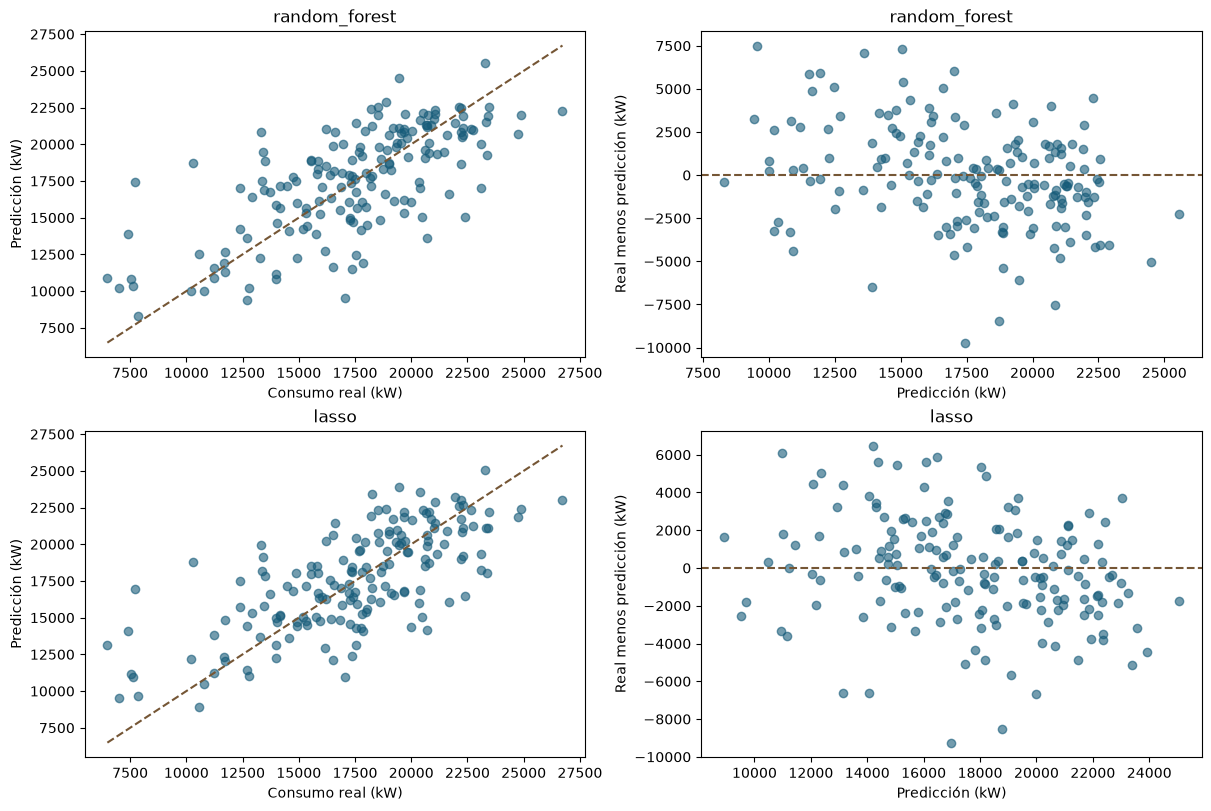

Tabla 7. Residuos por cuartil de consumo real de validación


In [5]:
mejor_lineal = min(("ridge", "lasso"), key=mae_validacion.get)
diagnosticos = ("random_forest", mejor_lineal)
fig, ejes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
grupos = pd.qcut(y_val, q=4, duplicates="drop")
resumen_residuos = []

for (real_eje, residuo_eje), nombre in zip(ejes, diagnosticos):
    prediccion = predicciones_val[nombre]
    residuos = y_val - prediccion
    limites = [min(y_val.min(), prediccion.min()), max(y_val.max(), prediccion.max())]

    real_eje.scatter(y_val, prediccion, alpha=0.6, color="#165b79")
    real_eje.plot(limites, limites, color="#755635", linestyle="--")
    real_eje.set(xlabel="Consumo real (kW)", ylabel="Predicción (kW)", title=nombre)
    residuo_eje.scatter(prediccion, residuos, alpha=0.6, color="#165b79")
    residuo_eje.axhline(0, color="#755635", linestyle="--")
    residuo_eje.set(xlabel="Predicción (kW)", ylabel="Real menos predicción (kW)", title=nombre)

    detalle = pd.DataFrame({"Consumo real (kW)": y_val, "Residuo (kW)": residuos,
                            "Error absoluto (kW)": residuos.abs(), "Cuartil": grupos})
    tabla = detalle.groupby("Cuartil", observed=True).agg(
        filas=("Residuo (kW)", "size"),
        consumo_minimo=("Consumo real (kW)", "min"),
        consumo_maximo=("Consumo real (kW)", "max"),
        residuo_medio=("Residuo (kW)", "mean"),
        mae=("Error absoluto (kW)", "mean"),
    ).reset_index(drop=True)
    tabla.index = pd.RangeIndex(1, len(tabla) + 1, name="Cuartil")
    resumen_residuos.append(tabla.reset_index().assign(Modelo=nombre))

plt.show()
mostrar_tabla(7, "Residuos por cuartil de consumo real de validación",
              pd.concat(resumen_residuos).set_index(["Modelo", "Cuartil"]))

Con los modelos ya ajustados, mezclamos una variable a la vez en las filas comunes de validación y medimos cuánto aumenta el MAE. Usamos las mismas repeticiones y semilla para que la escala sea comparable entre familias. Los resultados describen dependencia predictiva en este tramo y pueden repartirse entre variables correlacionadas. Las 14 entradas se mantienen en todos los modelos.

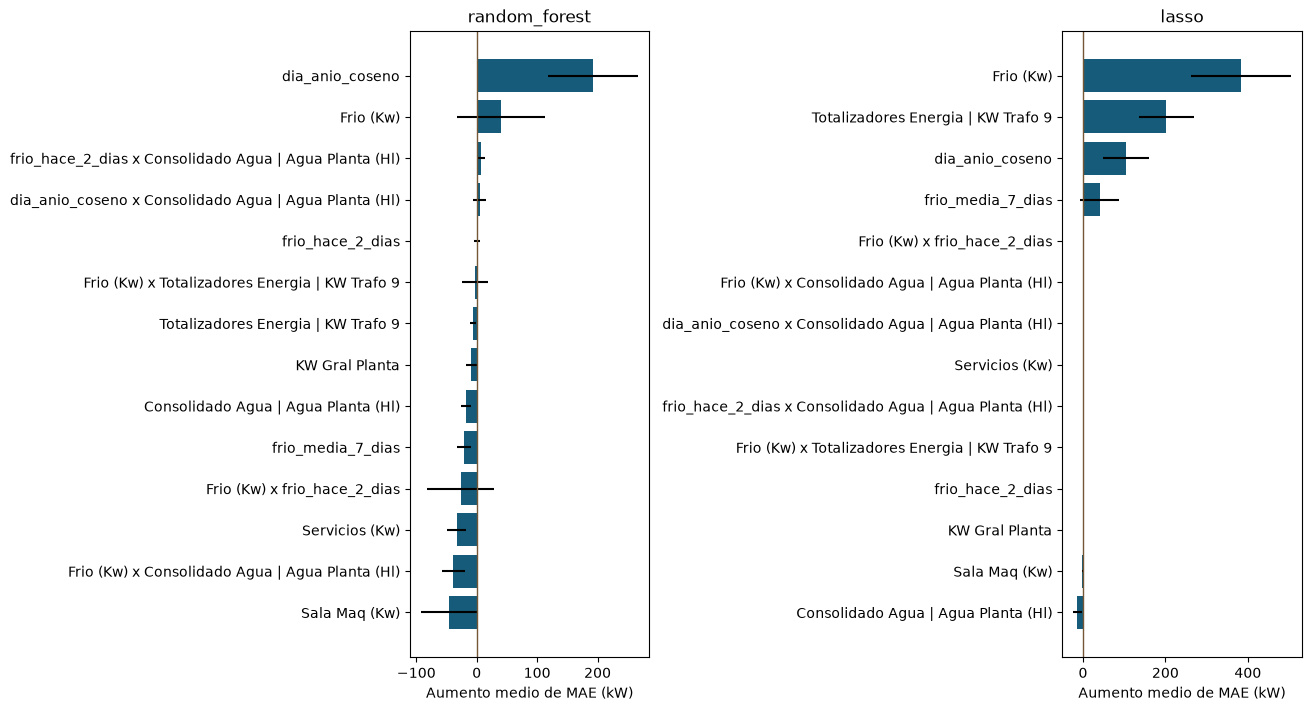

Tabla 8. Importancia por permutación en validación


In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 7), layout="constrained")
importancias = []
for eje, nombre in zip(ejes, diagnosticos):
    importancia = permutation_importance(
        modelos_ajustados[nombre], X_val, y_val, scoring="neg_mean_absolute_error",
        n_repeats=15, random_state=SEMILLA, n_jobs=1,
    )
    tabla = pd.DataFrame({
        "Variable": X_val.columns, "Aumento medio de MAE (kW)": importancia.importances_mean,
        "Desvío entre permutaciones (kW)": importancia.importances_std,
    }).sort_values("Aumento medio de MAE (kW)", ascending=False).reset_index(drop=True)
    importancias.append(tabla.assign(Modelo=nombre))
    eje.barh(tabla["Variable"], tabla["Aumento medio de MAE (kW)"],
             xerr=tabla["Desvío entre permutaciones (kW)"], color="#165b79")
    eje.axvline(0, color="#755635", linewidth=1)
    eje.invert_yaxis()
    eje.set(xlabel="Aumento medio de MAE (kW)", title=nombre)

plt.show()
mostrar_tabla(8, "Importancia por permutación en validación",
              pd.concat(importancias).set_index(["Modelo", "Variable"]))

## 6. Controles y conclusión

Comprobamos que se conservaron las entradas del linaje, que los pliegues respetan el orden y la fila de separación, y que los modelos y baselines se compararon sobre la misma cantidad de filas. Revisamos también que la corrida agregó al registro todas las configuraciones y una validación por modelo, con el mismo commit y el árbol limpio.

In [7]:
registro = pd.read_csv(RUTA_LOG).iloc[longitud_log_inicial:]
filas_cv = sum(len(candidatas) for candidatas in configuraciones.values())
filas_esperadas = pd.Series({
    (nombre, tramo): cantidad
    for nombre, candidatas in configuraciones.items()
    for tramo, cantidad in (("entrenamiento", len(candidatas)), ("validacion", 1))
}).sort_index()
filas_registradas = registro.groupby(["modelo", "tramo"]).size().sort_index()
huellas = json.loads((RAIZ / "data" / "checksums.json").read_text(encoding="utf-8"))
huella_dataset = huella(RUTA_DATASET_FINAL)
controles = pd.Series({
    "Se cargaron entrenamiento y validación": set(datos) == {"entrenamiento", "validacion"},
    "El CSV coincide con la huella del proyecto": huella_dataset == huellas["processed/dataset_final.csv"],
    "Las 14 variables coinciden y el objetivo está completo": (
        X_ent.shape[1] == 14 and X_ent.columns.equals(X_val.columns)
        and y_ent.notna().all() and validacion["y"].notna().all()
    ),
    "Los cinco pliegues son cronológicos y tienen una fila de separación": len(pliegues) == 5 and all(
        ajuste[-1] + 2 == evaluacion[0]
        and entrenamiento["fechas"].iloc[ajuste[-1]] <= entrenamiento["fechas"].iloc[evaluacion[0]]
        for ajuste, evaluacion in pliegues
    ),
    "El MAE cruzado ponderado coincide con el registrado": all(
        np.isclose(agregado[nombre], mejor["mae"]) for nombre, mejor in mejores.items()
    ),
    "Se registraron todas las configuraciones y una validación por modelo": (
        len(registro) == filas_cv + len(configuraciones)
        and filas_registradas.to_dict() == filas_esperadas.to_dict()
    ),
    "El registro tiene la misma cantidad de filas comunes que los baselines": (
        registro.loc[registro["tramo"] == "entrenamiento", "filas"].eq(pesos.sum()).all()
        and int(comunes_val.sum()) == bases_val["filas"]
        and registro.loc[registro["tramo"] == "validacion", "filas"].eq(bases_val["filas"]).all()
    ),
    "Cada fila nueva se registró con el commit, la semilla y el árbol limpio": (
        registro["commit"].eq(commit).all() and registro["semilla"].eq(SEMILLA).all()
        and registro["arbol_sin_commitear"].eq(False).all()
    ),
})
mostrar_tabla(9, "Controles de la corrida", controles.to_frame("Cumple"), precision=0)
assert controles.all(), controles[~controles]

ganador = min(resultados_val, key=mae_validacion.get)
print(f"El menor MAE de validación entre los modelos evaluados fue el de {ganador}.")

Tabla 9. Controles de la corrida


,Cumple
Se cargaron entrenamiento y validación,True
El CSV coincide con la huella del proyecto,True
Las 14 variables coinciden y el objetivo está completo,True
Los cinco pliegues son cronológicos y tienen una fila de separación,True
El MAE cruzado ponderado coincide con el registrado,True
Se registraron todas las configuraciones y una validación por modelo,True
El registro tiene la misma cantidad de filas comunes que los baselines,True
"Cada fila nueva se registró con el commit, la semilla y el árbol limpio",True


El menor MAE de validación entre los modelos evaluados fue el de lasso.


El orden de la tabla 6 sirve para aportar estos candidatos a la comparación del equipo. La tabla 5 muestra cuánto varía el error entre períodos de entrenamiento y la tabla 7 ayuda a detectar cambios de sesgo entre niveles de consumo. La validación ya se usó en la Fase 2 para seleccionar variables y cubre un período distinto del test oculto. El aporte termina con la comparación de candidatos previa a la elección y al reentrenamiento final del equipo.